# Quantum Metal tutorial 1.3 — four TransmonPockets in a ring of meandered buses (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/1-Overview/1.3-Build-a-4-qubit-chip.ipynb` (© IBM and Qiskit
Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/tut13_four_qubit_ring.md`. We distribute the rebuild under GPL-3.0. Four `TransmonPocket`s
(Q1 / Q3 at (±2.55, 0) mm, Q2 / Q4 at (0, ∓0.9) mm rotated 90°), each with four connection pads `a`–`d`, joined in a
ring by four `RouteMeander` buses (6.0 / 6.1 / 6.0 / 6.1 mm, ±150 µm asymmetry, fillet 90 µm). No readout,
launchpads or control lines: this is the core that tutorial 2.21 / circuit example 51 extend into a full chip.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options; the chip, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial 1.3 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` default 9 × 6 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with the QCT frame; the ring (≈ 6 × 2.7 mm) fits, so the die is centred on Metal's chip centre (`box=(750, −750, 8250, 6750)`) and every coordinate stays the source's (+4.5, +3) mm |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | `FakeJunction_01`, no inductance stated | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (the tutorial never exports a GDS) | the PDK band (chip `cheese: "auto"`) |
| buses | `RouteMeander` 6.0 / 6.1 mm | qcc fixed-length routes on Metal's own meander corner points, the same lengths |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** the qubits with the tutorial's options (`pad_width` 425 µm, `pocket_height` 650 µm, the four
connection pads with pad `b` 30 µm and `d` 50 µm high and pad `c` 200 µm wide), positions and orientations, every
bus's end pins and total length, and the meanders themselves: Metal's `RouteMeander` corner points (130 µm lead,
200 µm run pitch, 100 µm meander leads) are the waypoints, with Metal's 90 µm fillet, so the lengths are Metal's. The
10/6 µm CPW state (the tutorial's later variables cell, 25/12 µm and `pad_width` 450 µm, is a variant not built
here).

The notebook goes step by step: PDK → die → (pads) → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 4500, 3000                              # Metal's default 9 × 6 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 90                                           # Metal fillet
EPS = 0.05                                       # the waypoint path is Metal's length to < 0.05 µm: the fixed-length
                                                 # (λ/2 bus) route needs a target at or above it
RUNS = [1795, 1595, 1395, 1195, 995, 795, 595, 395]  # Metal's meander run positions (|x|, µm)


def bus(far, near, sx, sy):
    """Interior corner points of Metal's RouteMeander from a Q1/Q3 pad (|x| = 2125, |y| = 195) to a Q2/Q4 pad
    (|x| = 195, |y| = 475): runs alternating between |y| = far and near, mirrored by the signs (sx, sy)."""
    pts = [(1795, 195)]
    for k, x in enumerate(RUNS):
        y = far if k % 2 == 0 else near
        if k:
            pts.append((x, pts[-1][1]))
        pts.append((x, y))
    pts.append((195, pts[-1][1]))
    return [P(sx * x, sy * y) for x, y in pts]

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame; there are no pads for the pad rule; the four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its 9 × 6 mm chip
on (0, 0); the 7.5 mm die is placed on that chip's centre, (4.5, 3) mm, so `P(x, y)` = Metal + (4500, 3000).

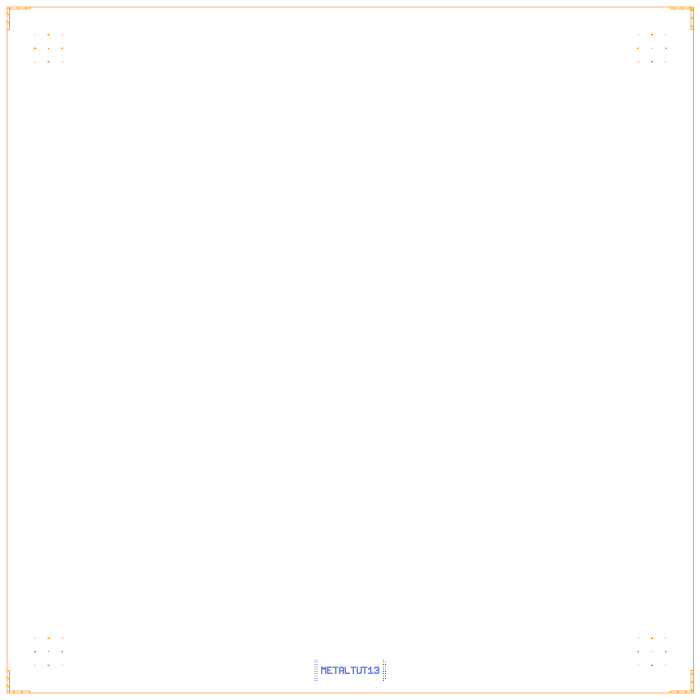

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_step_die.png')

In [4]:
d = Designer("tut13_four_qubit_ring", box=(750, -750, 8250, 6750), chip={"name_chip": "MetalTut13"}, live=LIVE)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "tut13_four_qubit_ring_step_die.png", size=(700, 700), width=350)

## 4 · Pads

Tutorial 1.3 has no launchpads, readouts or control lines (they come in tutorial 2.21 / example 51), so the PDK pad
rule (outer etch edge 100 µm from the die edge) has nothing to place here; `pads_md(d)` in step 7 confirms there are
none.

## 5 · Components: the four qubits

**The qubits.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm-high pocket and four connection pads `a`–`d` at the corners (pad `b` 30 µm and `d`
50 µm high, pad `c` 200 µm wide: the tutorial varies them on purpose). Q2 / Q4 are rotated 90°.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source's `FakeJunction_01` states no value, so every qubit gets the PDK nominal junction
(fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


Q1 ports: ['a', 'b', 'c', 'd', 'squid_a', 'squid_b']


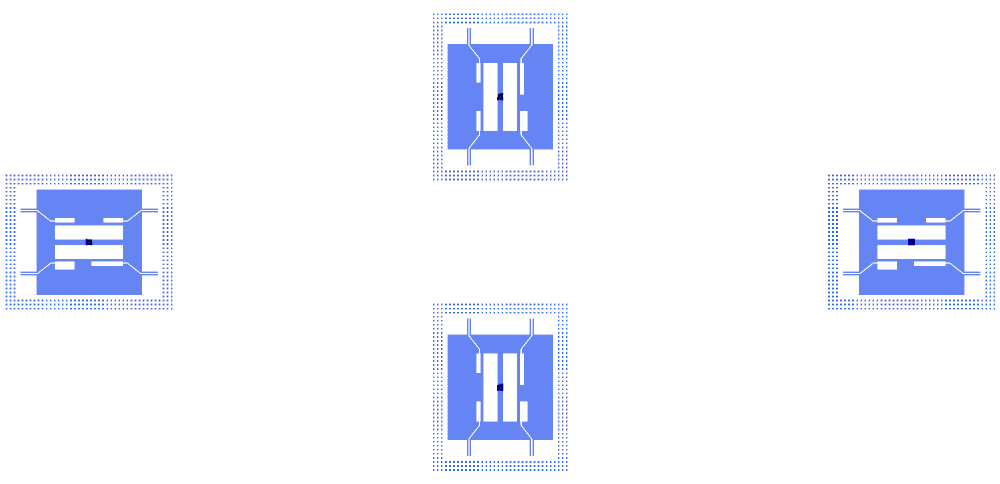

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_step_parts.png')

In [5]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    opts = dict(pad_width=425, pocket_height=650, junction=JUNCTION, **JJ_PARAMS,
                connection_pads={"a": {"loc_W": 1, "loc_H": 1}, "b": {"loc_W": -1, "loc_H": 1, "pad_height": 30},
                                 "c": {"loc_W": 1, "loc_H": -1, "pad_width": 200},
                                 "d": {"loc_W": -1, "loc_H": -1, "pad_height": 50}})
    q = {k: d.add(f"Q{k}", "metal:TransmonPocket", at=P(x, y), rot=r, **opts)
         for k, x, y, r in ((1, 2550, 0, 0), (2, 0, -900, 90), (3, -2550, 0, 0), (4, 0, 900, 90))}
print("Q1 ports:", sorted(q[1].ports))
snap(d, OUT / "tut13_four_qubit_ring_step_parts.png", box=P(-3100, -1500) + P(3100, 1500), size=(1000, 484),
     width=500)

## 6 · Routes: the four ring buses

Each bus runs from a Q1 / Q3 pad to a Q2 / Q4 pad. `meander=6000 + EPS` (or 6100) makes a fixed-length route whose
waypoints are Metal's own `RouteMeander` corner points (`bus()` in the setup cell): runs at 200 µm pitch alternating
between two distances from the axis, mirrored for each quadrant. The waypoint path is already Metal's length, so the
router only checks it (and adds the 0.05 µm). As λ/2 buses (open at both pads) they sit near 10.5 GHz.

**Sim groups:** the whole ring (nothing leaves the box) and Q1 alone (the box cuts its two buses once each), both
Q3D C-matrix jobs.

{'cpw1': 6000.0, 'cpw2': 6100.0, 'cpw3': 6000.0, 'cpw4': 6100.0} (Metal 6000 / 6100 / 6000 / 6100 µm)


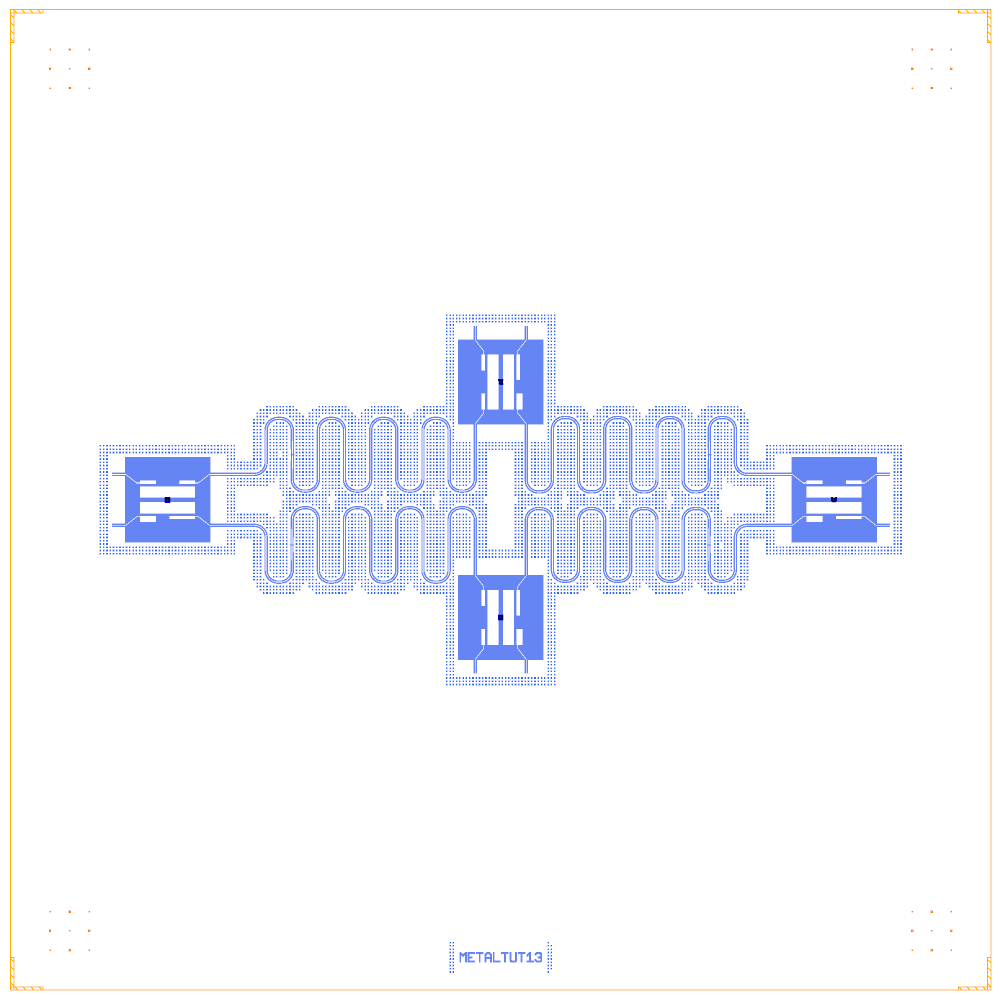

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_step_routes.png')

In [6]:
with d.batch():
    # buses: Metal's start / end pins and meander corners (runs 67.08 … 622.92 µm off the axis for 6.0 mm,
    # 60.83 … 629.17 µm for 6.1 mm)
    d.route("cpw1", q[1].d, q[2].c, meander=6000 + EPS, r=R, nodes=bus(622.92, 67.08, 1, -1))
    d.route("cpw2", q[3].c, q[2].a, meander=6100 + EPS, r=R, nodes=bus(629.17, 60.83, -1, -1))
    d.route("cpw3", q[3].a, q[4].b, meander=6000 + EPS, r=R, nodes=bus(622.92, 67.08, -1, 1))
    d.route("cpw4", q[1].b, q[4].d, meander=6100 + EPS, r=R, nodes=bus(629.17, 60.83, 1, 1))
# FEM boxes: the whole ring (nothing leaves it), and Q1 alone (the box cuts its two buses once each)
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
d.sim_group("Q1", ["Q1"], margin_um=50, analyses=["q3d_cmatrix"])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()}, "(Metal 6000 / 6100 / 6000 / 6100 µm)")
snap(d, OUT / "tut13_four_qubit_ring_step_routes.png", size=(1000, 1000), width=400)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre. The die was placed on the source's
chip centre and the ring is symmetric, so nothing moves. Then the design is saved: the JSON is the deliverable.

In [7]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
display(Markdown(pads_md(d)))
DESIGN = d.save(OUT / "tut13_four_qubit_ring.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

<Designer tut13_four_qubit_ring: 4 instances, 4 routes, live=False> → examples\designs\metal\tut13_four_qubit_ring.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, sixteen `dangling_port` warnings: the eight junction attachment points
(`Q<k>.squid_a` / `squid_b`: the qubit cell draws the junction itself) and the eight outward pads (Q1 / Q3 `a`, `c`;
Q2 / Q4 `b`, `d`), which have no line, as in the source; and **no PDK design warnings** (no pads, the nominal
junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [8]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 16 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 16 | Q1.a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` gives two floating pad nodes with the
junction between them and a node per connection pad (the four outward pads couple to the pads but carry nothing, as
in the source); each bus between two pads is a λ/2 `TLres` (6.0 mm ≈ 10.67 GHz, 6.1 mm ≈ 10.49 GHz bare). The port
map shows which node each of Q1's ports landed on.

In [9]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith("Q1.")})

**21 nodes · 68 branches · 0 controls · 8 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.a` | `Q1.a` |
| `Q1.b` | `Q1.b`, `Q4.d` |
| `Q1.c` | `Q1.c` |
| `Q1.d` | `Q1.d`, `Q2.c` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.a` | `Q2.a`, `Q3.c` |
| `Q2.b` | `Q2.b` |
| `Q2.d` | `Q2.d` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.a` | `Q3.a`, `Q4.b` |
| `Q3.b` | `Q3.b` |
| `Q3.d` | `Q3.d` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.a` | `Q4.a` |
| `Q4.c` | `Q4.c` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_a` | C | `Q1.island1` – `Q1.a` | 17 fF |
| `Cf_Q1_a` | C | `Q1.island2` – `Q1.a` | 1.8 fF |
| `Cc_Q1_a` | C | `Q1.a` – `gnd` | 34.3 fF |
| `Cg_Q1_b` | C | `Q1.island1` – `Q1.b` | 17 fF |
| `Cf_Q1_b` | C | `Q1.island2` – `Q1.b` | 1.8 fF |
| `Cc_Q1_b` | C | `Q1.b` – `gnd` | 34.3 fF |
| `Cg_Q1_c` | C | `Q1.island2` – `Q1.c` | 24.8 fF |
| `Cf_Q1_c` | C | `Q1.island1` – `Q1.c` | 2.6 fF |
| `Cc_Q1_c` | C | `Q1.c` – `gnd` | 37.5 fF |
| `Cg_Q1_d` | C | `Q1.island2` – `Q1.d` | 16.8 fF |
| `Cf_Q1_d` | C | `Q1.island1` – `Q1.d` | 1.8 fF |
| `Cc_Q1_d` | C | `Q1.d` – `gnd` | 37.6 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_a` | C | `Q2.island1` – `Q2.a` | 17 fF |
| `Cf_Q2_a` | C | `Q2.island2` – `Q2.a` | 1.8 fF |
| `Cc_Q2_a` | C | `Q2.a` – `gnd` | 34.3 fF |
| `Cg_Q2_b` | C | `Q2.island1` – `Q2.b` | 17 fF |
| `Cf_Q2_b` | C | `Q2.island2` – `Q2.b` | 1.8 fF |
| `Cc_Q2_b` | C | `Q2.b` – `gnd` | 34.3 fF |
| `Cg_Q2_c` | C | `Q2.island2` – `Q1.d` | 24.8 fF |
| `Cf_Q2_c` | C | `Q2.island1` – `Q1.d` | 2.6 fF |
| `Cc_Q2_c` | C | `Q1.d` – `gnd` | 37.5 fF |
| `Cg_Q2_d` | C | `Q2.island2` – `Q2.d` | 16.8 fF |
| `Cf_Q2_d` | C | `Q2.island1` – `Q2.d` | 1.8 fF |
| `Cc_Q2_d` | C | `Q2.d` – `gnd` | 37.6 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 34.3 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 34.3 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 26.2 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_a` | C | `Q3.island1` – `Q3.a` | 17 fF |
| `Cf_Q3_a` | C | `Q3.island2` – `Q3.a` | 1.8 fF |
| `Cc_Q3_a` | C | `Q3.a` – `gnd` | 34.3 fF |
| `Cg_Q3_b` | C | `Q3.island1` – `Q3.b` | 17 fF |
| `Cf_Q3_b` | C | `Q3.island2` – `Q3.b` | 1.8 fF |
| `Cc_Q3_b` | C | `Q3.b` – `gnd` | 34.3 fF |
| `Cg_Q3_c` | C | `Q3.island2` – `Q2.a` | 24.8 fF |
| `Cf_Q3_c` | C | `Q3.island1` – `Q2.a` | 2.6 fF |
| `Cc_Q3_c` | C | `Q2.a` – `gnd` | 37.5 fF |
| `Cg_Q3_d` | C | `Q3.island2` – `Q3.d` | 16.8 fF |
| `Cf_Q3_d` | C | `Q3.island1` – `Q3.d` | 1.8 fF |
| `Cc_Q3_d` | C | `Q3.d` – `gnd` | 37.6 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 34.3 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 34.3 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 26.2 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_a` | C | `Q4.island1` – `Q4.a` | 17 fF |
| `Cf_Q4_a` | C | `Q4.island2` – `Q4.a` | 1.8 fF |
| `Cc_Q4_a` | C | `Q4.a` – `gnd` | 34.3 fF |
| `Cg_Q4_b` | C | `Q4.island1` – `Q3.a` | 17 fF |
| `Cf_Q4_b` | C | `Q4.island2` – `Q3.a` | 1.8 fF |
| `Cc_Q4_b` | C | `Q3.a` – `gnd` | 34.3 fF |
| `Cg_Q4_c` | C | `Q4.island2` – `Q4.c` | 24.8 fF |
| `Cf_Q4_c` | C | `Q4.island1` – `Q4.c` | 2.6 fF |
| `Cc_Q4_c` | C | `Q4.c` – `gnd` | 37.5 fF |
| `Cg_Q4_d` | C | `Q4.island2` – `Q1.b` | 16.8 fF |
| `Cf_Q4_d` | C | `Q4.island1` – `Q1.b` | 1.8 fF |
| `Cc_Q4_d` | C | `Q1.b` – `gnd` | 37.6 fF |
| `cpw1` | TLres | `Q1.d` – `gnd` | lambda/2, 6000 µm, 10.503 GHz |
| `cpw2` | TLres | `Q2.a` – `gnd` | lambda/2, 6100 µm, 10.331 GHz |
| `cpw3` | TLres | `Q3.a` – `gnd` | lambda/2, 6000 µm, 10.503 GHz |
| `cpw4` | TLres | `Q1.b` – `gnd` | lambda/2, 6100 µm, 10.331 GHz |

**Unconnected ports:** `Q1.a`, `Q1.c`, `Q2.b`, `Q2.d`, `Q3.b`, `Q3.d`, `Q4.a`, `Q4.c`

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.a': 'Q1.a', 'Q1.b': 'Q1.b', 'Q1.c': 'Q1.c', 'Q1.d': 'Q1.d'}


## 10 · LOM simulation

QuCat solves each sub-circuit's normal modes; QuTiP diagonalises the dressed Hamiltonian for f_q and α and the static
ZZ of each qubit pair. Each bus is simulated with the two qubits it joins.

With the PDK junction (6.73 nH, 15 fF) the qubits sit near 7.05 GHz linear (6.8 GHz dressed), ≈ 2.3 GHz below the
λ/2 buses (dispersive).
They share the junction but not their pads (pad `b` 30 µm and `d` 50 µm high, `c` 200 µm wide), so the pads each bus
lands on load the two qubits differently: a pair whose qubits come out within a few MHz hybridises through its bus
(ZZ "hybridised", not defined). The tutorial states no targets.

In [10]:
ring = {"Q1+cpw1+Q2": ["Q1", "cpw1", "Q2"], "Q3+cpw2+Q2": ["Q3", "cpw2", "Q2"],
        "Q3+cpw3+Q4": ["Q3", "cpw3", "Q4"], "Q1+cpw4+Q4": ["Q1", "cpw4", "Q4"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

**Q1+cpw1+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 7.0334 | 0 | 234.5 | J_Q2 0.96, J_Q1 0.03 |
| Q1 | qubit | 7.0756 | 0 | 239.8 | J_Q1 0.96, J_Q2 0.03 |
| cpw1 | resonator | 9.3904 | 0 | 0.0 | cpw1 0.99 |

**Q3+cpw2+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q3 | qubit | 7.0320 | 0 | 217.6 | J_Q3 0.92, J_Q2 0.07, cpw2 0.01 |
| Q2 | qubit | 7.0655 | 0 | 222.4 | J_Q2 0.93, J_Q3 0.07 |
| cpw2 | resonator | 9.2816 | 0 | 0.0 | cpw2 0.99 |

**Q3+cpw3+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q3 | qubit | 7.0575 | 0 | 126.3 | J_Q3 0.50, J_Q4 0.50 |
| Q4 | qubit | 7.0698 | 0 | 128.7 | J_Q4 0.50, J_Q3 0.50 |
| cpw3 | resonator | 9.4875 | 0 | 0.0 | cpw3 0.99 |

**Q1+cpw4+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 7.0605 | 0 | 182.1 | J_Q1 0.83, J_Q4 0.17 |
| Q4 | qubit | 7.0767 | 0 | 184.7 | J_Q4 0.83, J_Q1 0.17 |
| cpw4 | resonator | 9.3181 | 0 | 0.0 | cpw4 0.99 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+cpw1+Q2 | Q1-Q2 | 438.4 | yes | no |
| Q3+cpw2+Q2 | Q2-Q3 | 545.3 | yes | no |
| Q3+cpw3+Q4 | Q3-Q4 | – | yes | yes |
| Q1+cpw4+Q4 | Q1-Q4 | 275.2 | yes | no |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for both sim groups: `ring` (the four qubits with their buses: the island, pad and bus
capacitances and the pad-to-pad couplings) and `Q1` (Q1 alone: its C_Σ and pad capacitances, the box cutting its two
buses).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [11]:
jobs = export_sims(DESIGN)
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| ring | `build/jobs/tut13_four_qubit_ring_ring_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · junction · `Q3.junction`<br>4 · junction · `Q4.junction`<br>5 · waveguide · `Q1.d`<br>6 · waveguide · `Q2.c`<br>7 · waveguide · `Q3.c`<br>8 · waveguide · `Q2.a`<br>9 · waveguide · `Q3.a`<br>10 · waveguide · `Q4.b`<br>11 · waveguide · `Q1.b`<br>12 · waveguide · `Q4.d` | `Q1.island2`, `Q2.island2`, `Q3.island2`, `Q4.island2`, `Q1.d`, `Q2.c`, `Q3.c`, `Q2.a`, `Q3.a`, `Q4.b`, `Q1.b`, `Q4.d`, `Q2.island1`, `Q3.island1`, `Q1.island1`, `Q4.island1` |
| Q1 | `build/jobs/tut13_four_qubit_ring_Q1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · edge · `cpw1`<br>3 · edge · `cpw4` | `Q1.island2`, `cpw1`, `cpw4`, `Q1.island1` |

In [12]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['ring', 'Q1'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [13]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for ring · q3d, Q1 · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's `pad_width`, 425 → 450 µm (the value of the tutorial's own later variant) —
rebuild, re-run the LOM of Q1–cpw1–Q2 and compare. Wider pads add to Q1's C_Σ: Q1 moves down (≈ 90 MHz, past Q2), |α|
shrinks, and the Q1–Q2 detuning that sets the static ZZ changes.

In [14]:
d2 = design_copy(DESIGN)
d2["Q1"].set(pad_width=450)                      # 425 → 450 µm
group = {"Q1+cpw1+Q2": ring["Q1+cpw1+Q2"]}
after = simulate_groups(d2, group, max_modes=3)
display(Markdown(params_delta_md({"Q1+cpw1+Q2": coupled["Q1+cpw1+Q2"]}, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+cpw1+Q2: Q2.f_q_GHz` | 6.7696 | 6.7714 | +0.001759 |
| `Q1+cpw1+Q2: Q2.alpha_MHz` | -275.65 | -279.21 | -3.56 |
| `Q1+cpw1+Q2: cpw1.chi_MHz` | -3.6578 | -3.6815 | -0.0237 |
| `Q1+cpw1+Q2: Q1.f_q_GHz` | 6.8076 | 6.7211 | -0.08646 |
| `Q1+cpw1+Q2: Q1.alpha_MHz` | -284.3 | -273.15 | +11.15 |
| `Q1+cpw1+Q2: cpw1.f_GHz` | 9.3871 | 9.389 | +0.001902 |
| `Q1+cpw1+Q2: cpw1.kappa_MHz` | 0 | 0 | +0 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Tutorial 1.3 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [15]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\tut13_four_qubit_ring.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7055 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 7047 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7044 holes on the mask.

→ `build/tut13_four_qubit_ring_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot after the buses are added); Q1 with its four pads; its trilayer
junction; the cpw1 meander; the **fab mask** round Q1 (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are
read from the design.

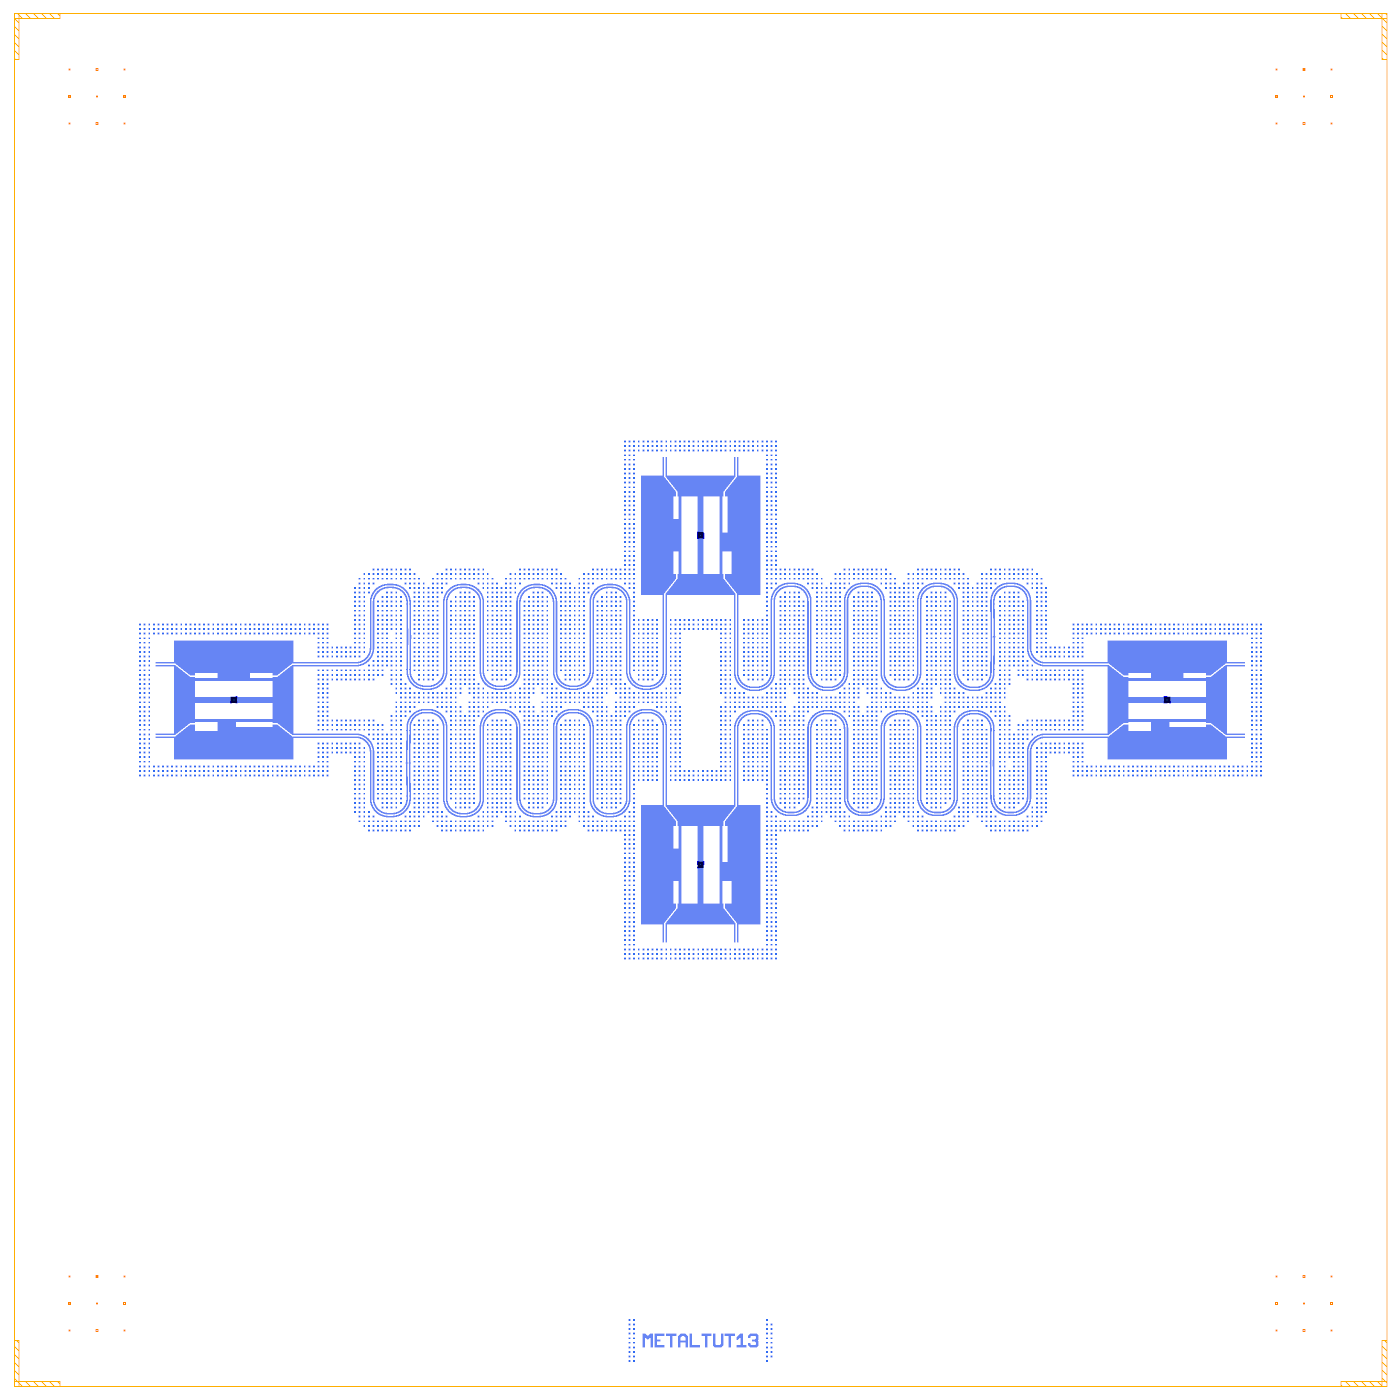

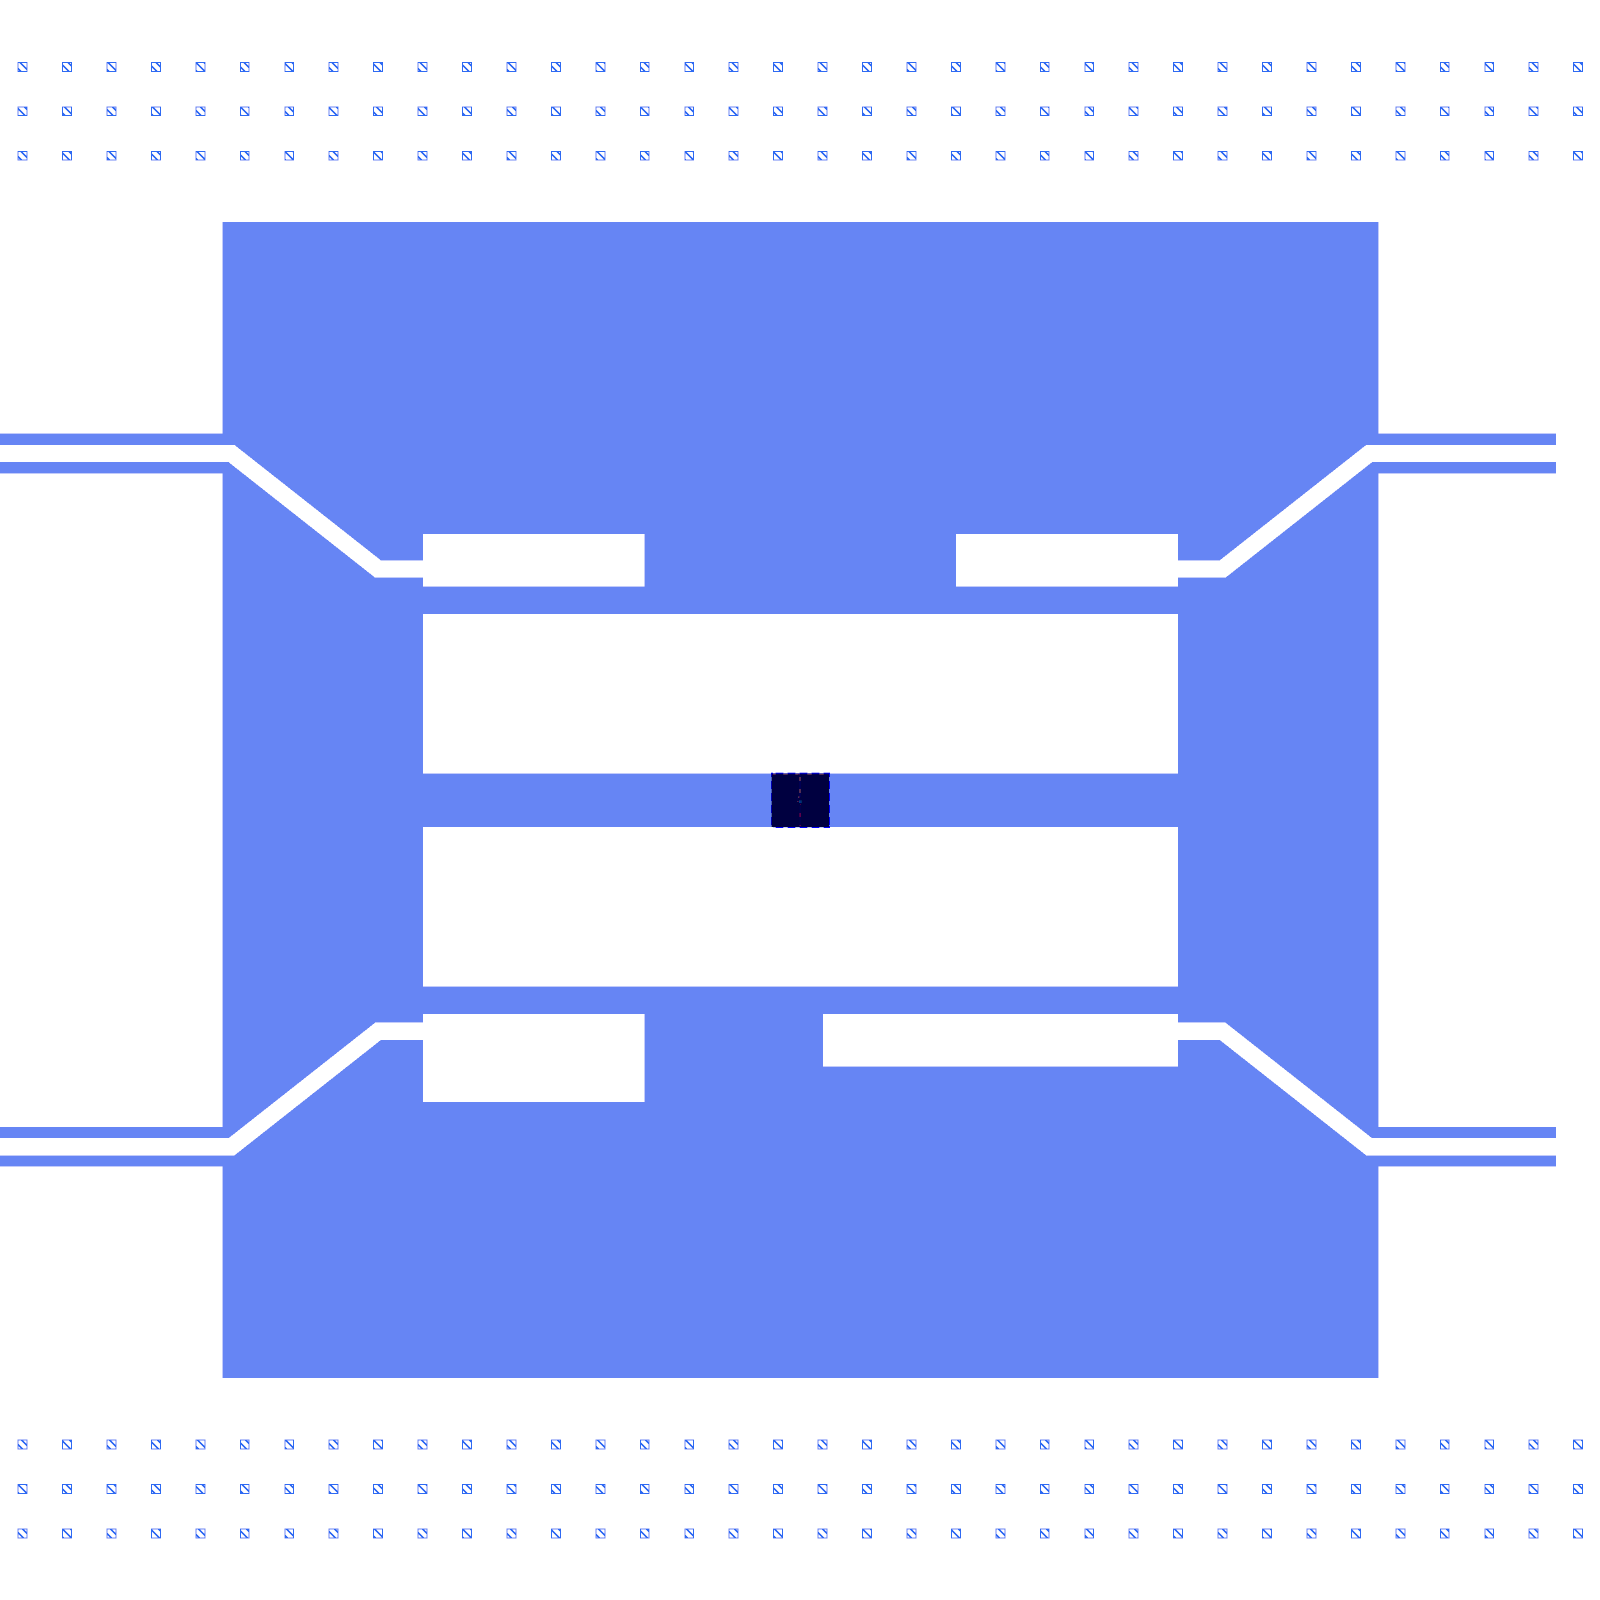

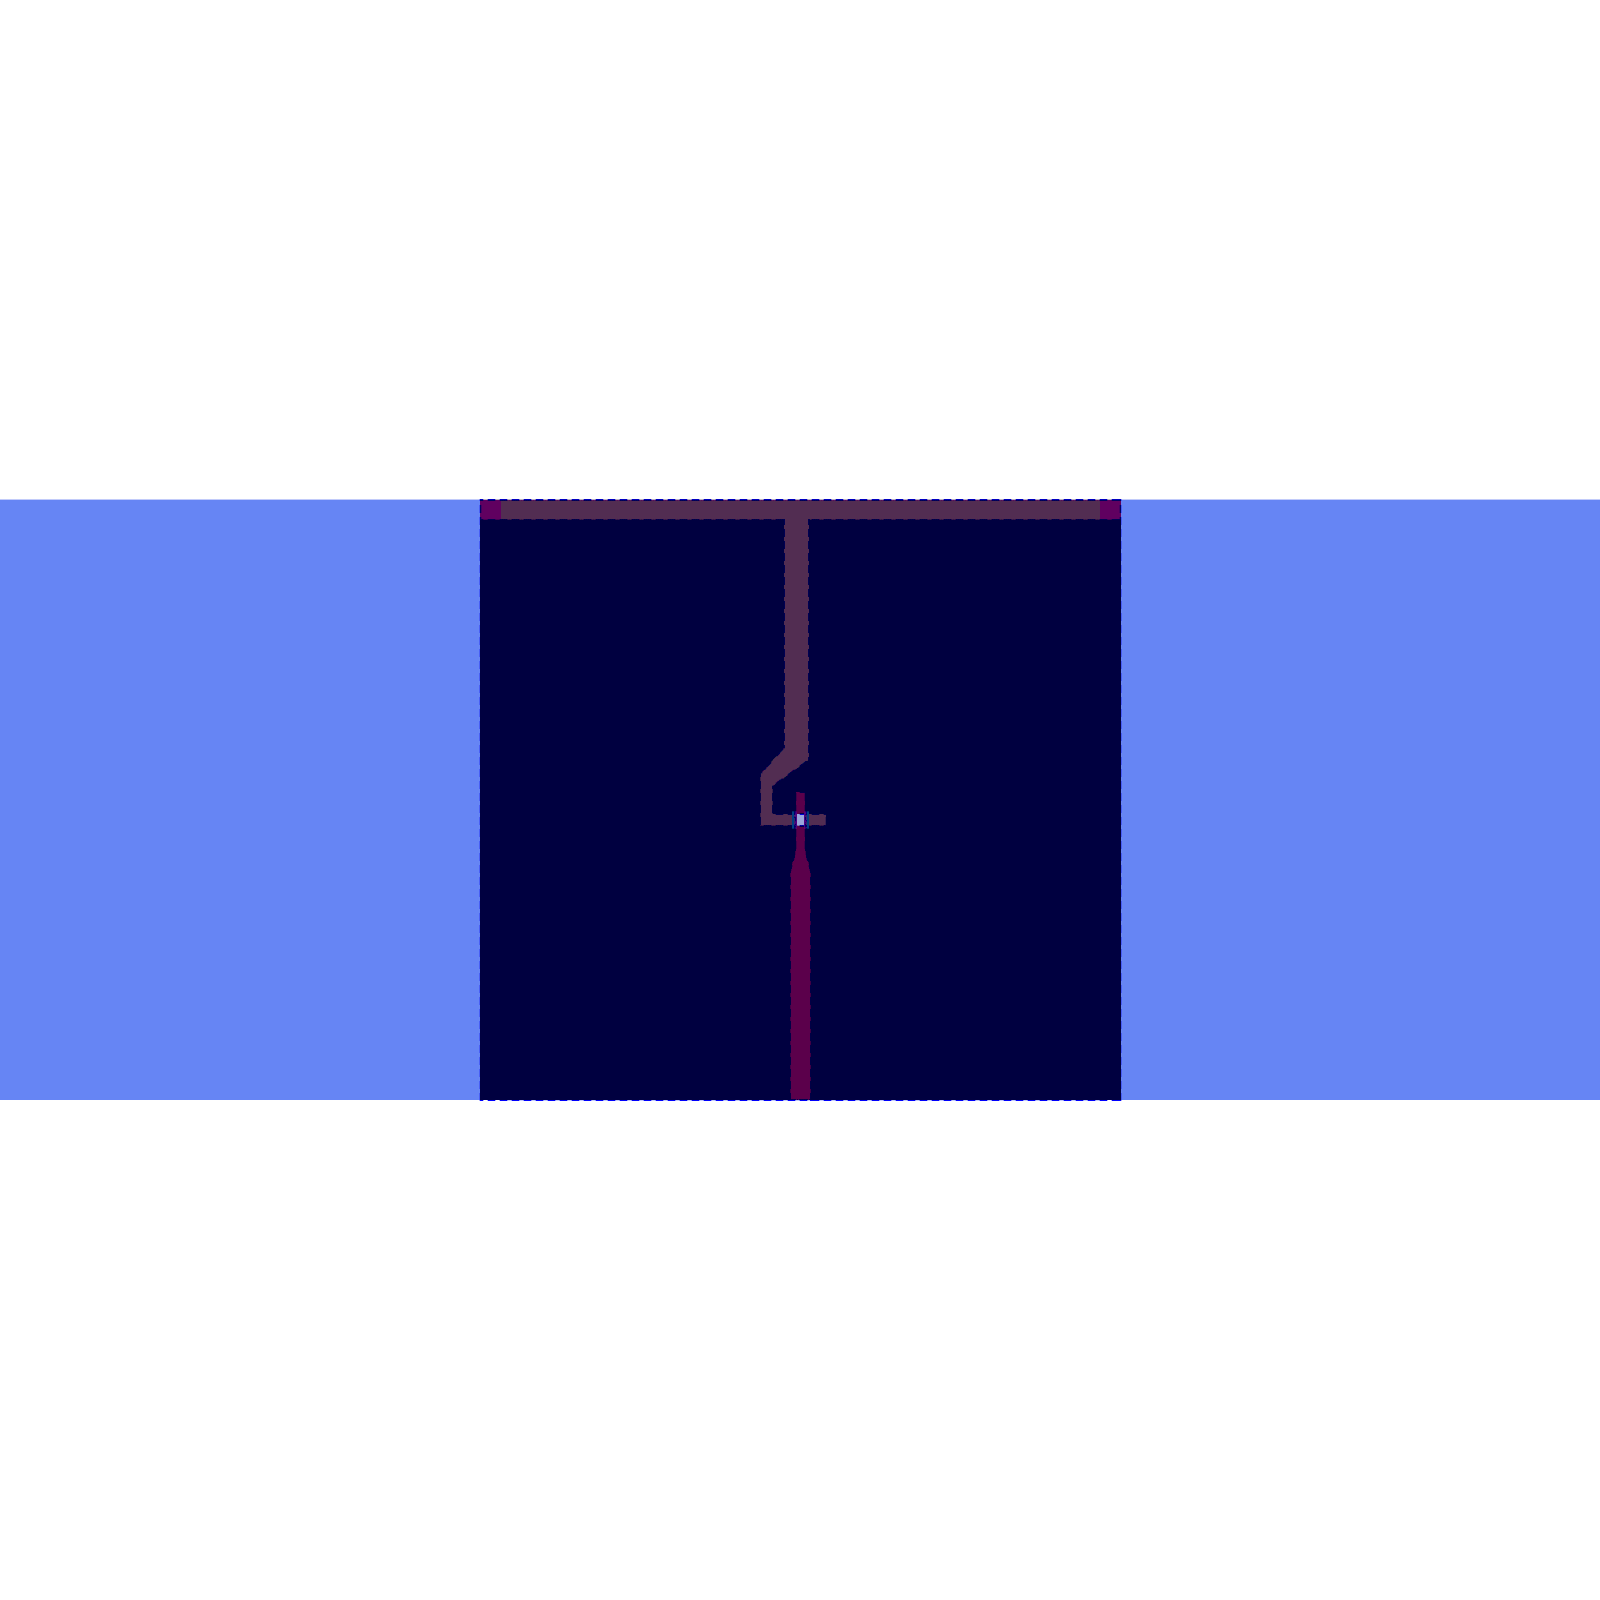

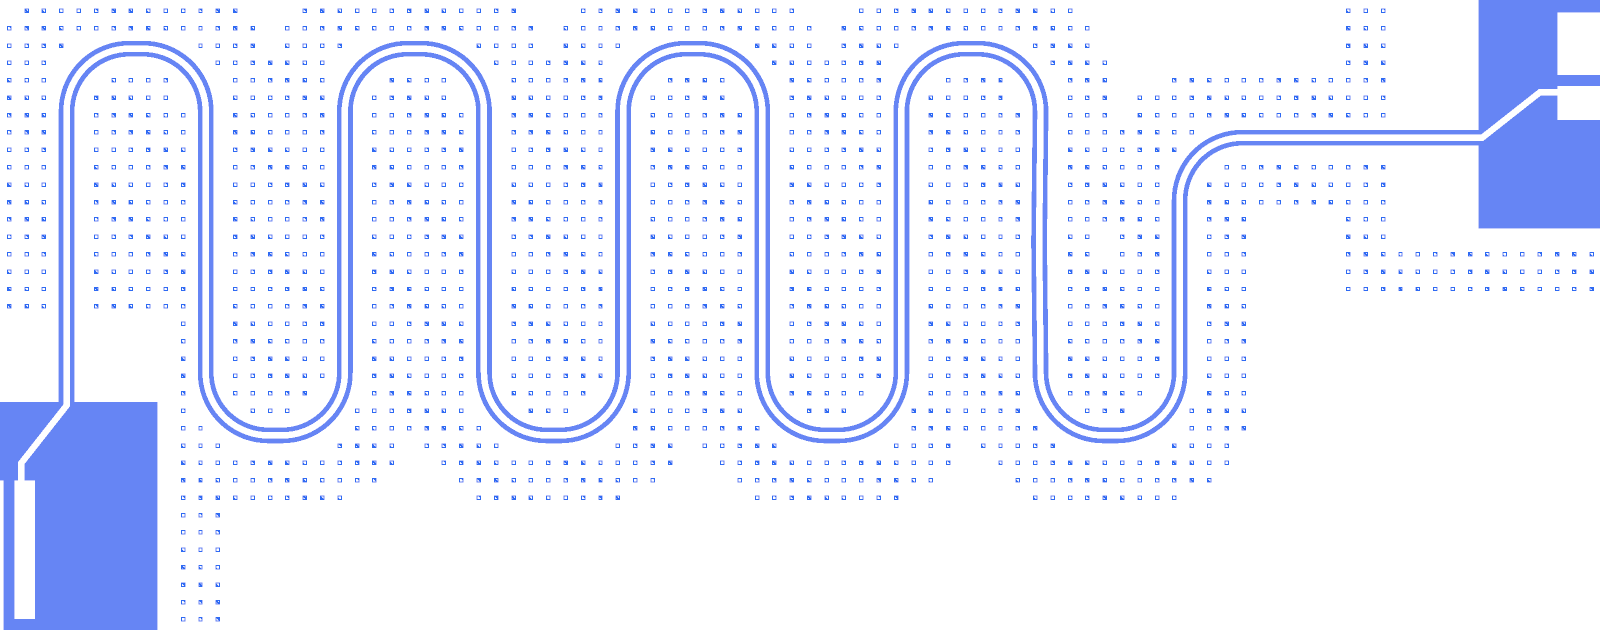

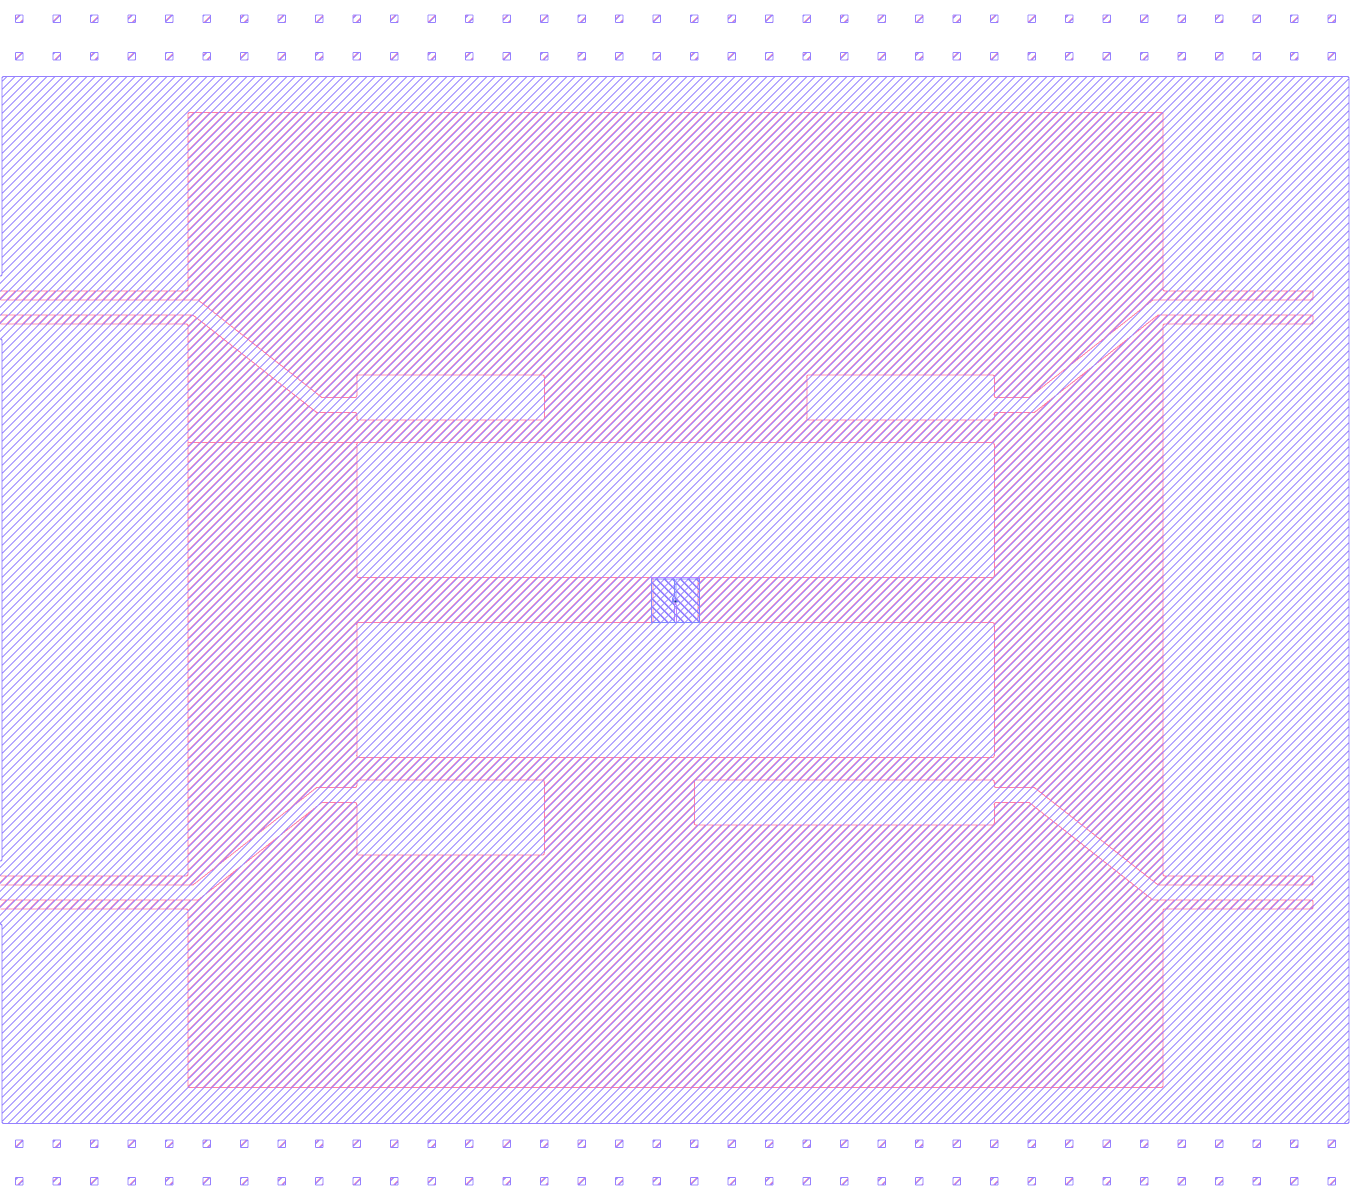

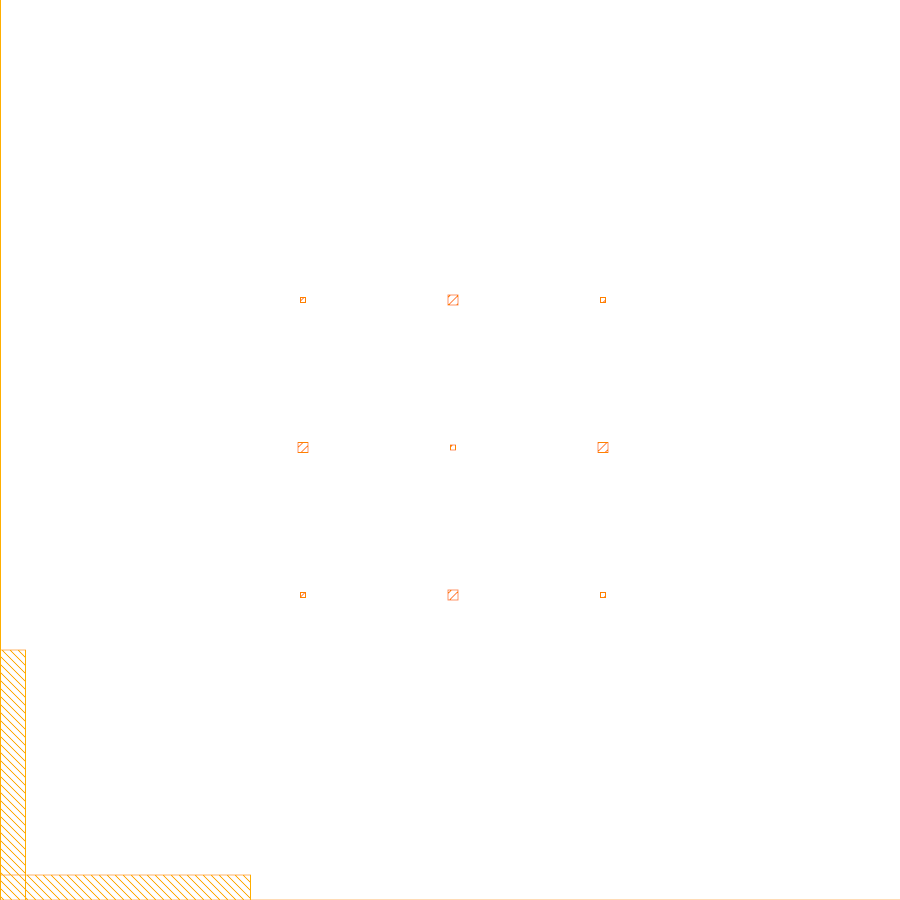

In [16]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "tut13_four_qubit_ring.png", size=(1400, 1400))
show_snapshot(d, OUT / "tut13_four_qubit_ring_q1.png", box=(qx - 450, qy - 400, qx + 450, qy + 400), width=420)
show_snapshot(d, OUT / "tut13_four_qubit_ring_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "tut13_four_qubit_ring_bus.png", box=(qx - 2450, qy - 900, qx - 150, qy), size=(1600, 630),
              width=640)
snap_file(Path("build") / "tut13_four_qubit_ring_fab.oas", OUT / "tut13_four_qubit_ring_cheese.png",
          box=(qx - 450, qy - 400, qx + 450, qy + 400), size=(1350, 1200), width=420)
show_snapshot(d, OUT / "tut13_four_qubit_ring_frame.png", box=(750, -750, 1650, 150), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, positions and orientations, the bus end pins, Metal's meander corner points and lengths (6000 / 6100 / 6000 / 6100 µm), the sim groups |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame (on the source's chip centre); sapphire stack; trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed); no pads to place |
| differs | f_q with the PDK junction instead of the pre-rebuild 10 nH assumption (6.34–6.39 GHz) |
| LOM (this run) | f_q 6.77–6.81 GHz dressed (QuCat 7.03–7.08 linear), α −276…−284 MHz; buses 9.28–9.49 GHz dressed; χ(cpw1) −3.7 MHz; static ZZ Q1–Q2 438 kHz, Q2–Q3 545 kHz, Q1–Q4 275 kHz, Q3–Q4 hybridised |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |